# New Section
print("Welcome to RevenueRadar!")
print("Our goal: turn transactions into business insights.")

In [3]:
print("Welcome to RevenueRadar!")
print("Our goal: turn transactions into business insights.")

Welcome to RevenueRadar!
Our goal: turn transactions into business insights.


In [5]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nBasic statistics:")
df.describe()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Basic statistics:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [7]:

print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())

print("Negative prices:", (df["UnitPrice"] < 0).sum())
print("Zero prices:", (df["UnitPrice"] == 0).sum())

print("\nInvoices beginning with C:")
print(df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("\nSample negative-quantity records:")
display(df[df["Quantity"] < 0].head(10))


Negative quantities: 10624
Zero quantities: 0
Negative prices: 2
Zero prices: 2515

Invoices beginning with C:
9288

Sample negative-quantity records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [8]:
# Show all rows where the unit price is negative
display(df[df["UnitPrice"] < 0])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [9]:
# Count rows with missing customer IDs
missing_customers = df["CustomerID"].isnull().sum()

# Calculate the percentage of rows with missing customer IDs
missing_percentage = (missing_customers / len(df)) * 100

# Display the results
print("Rows with missing CustomerID:", missing_customers)
print("Percentage missing:", round(missing_percentage, 2), "%")

Rows with missing CustomerID: 135080
Percentage missing: 24.93 %


In [10]:
# Find all rows that are exact duplicates
duplicates = df[df.duplicated(keep=False)]

# Count how many rows belong to duplicate groups
print("Total rows in duplicate groups:", len(duplicates))

# Display 10 examples
display(duplicates.head(10))

Total rows in duplicate groups: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [11]:
# Make a copy of the original dataset
df_clean = df.copy()

# Remove exact duplicate rows, keeping the first occurrence
df_clean = df_clean.drop_duplicates()

# Compare the original and cleaned datasets
print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Original rows: 541909
Rows after removing duplicates: 536641
Rows removed: 5268


In [12]:
print(df_clean.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [13]:
missing_percentage = (df_clean.isnull().sum() / len(df_clean)) * 100

print(missing_percentage.round(2))

InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     25.16
Country         0.00
dtype: float64


In [14]:
display(df_clean[df_clean["Description"].isnull()].head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [15]:
print("Negative quantities:", (df_clean["Quantity"] < 0).sum())
print("Zero prices:", (df_clean["UnitPrice"] == 0).sum())
print("Cancelled invoices:", df_clean["InvoiceNo"].astype(str).str.startswith("C").sum())

Negative quantities: 10587
Zero prices: 2510
Cancelled invoices: 9251


In [16]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

display(df_clean[["Quantity", "UnitPrice", "Revenue"]].head())

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [17]:
print("Total revenue:", df_clean["Revenue"].sum())

Total revenue: 9726006.953999998


In [18]:
positive_sales = df_clean[df_clean["Quantity"] > 0]

print("Positive-quantity revenue:", positive_sales["Revenue"].sum())

Positive-quantity revenue: 10619986.684


In [19]:
cancelled = df_clean[
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancellation-related revenue:", cancelled["Revenue"].sum())

Cancellation-related revenue: -893979.7300000001


In [20]:
print("C-invoice rows with negative quantity:",
      (cancelled["Quantity"] < 0).sum())

print("C-invoice rows with positive quantity:",
      (cancelled["Quantity"] > 0).sum())

C-invoice rows with negative quantity: 9251
C-invoice rows with positive quantity: 0


In [21]:
gross_sales = df_clean[df_clean["Quantity"] > 0]["Revenue"].sum()

print("Gross sales revenue:", round(gross_sales, 2))

Gross sales revenue: 10619986.68


In [22]:
zero_price = df_clean[df_clean["UnitPrice"] == 0]

print("Zero-priced rows:", len(zero_price))
print("With positive quantity:", (zero_price["Quantity"] > 0).sum())
print("With negative quantity:", (zero_price["Quantity"] < 0).sum())

Zero-priced rows: 2510
With positive quantity: 1174
With negative quantity: 1336


In [23]:
display(zero_price[zero_price["Quantity"] > 0].head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,0.0
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom,0.0
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0
4348,536765,84952C,NaN,19,2010-12-02 14:43:00,0.0,NaN,United Kingdom,0.0


In [24]:
negative_non_c = df_clean[
    (df_clean["Quantity"] < 0) &
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
]

print("Negative-quantity rows without C invoice:", len(negative_non_c))
display(negative_non_c.head(10))

Negative-quantity rows without C invoice: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,-0.0
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom,-0.0
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom,-0.0
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom,-0.0
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom,-0.0
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom,-0.0
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom,-0.0


In [25]:
display(df_clean.nlargest(10, "UnitPrice")[
    ["InvoiceNo", "Description", "Quantity", "UnitPrice", "Revenue"]
])

,InvoiceNo,Description,Quantity,UnitPrice,Revenue
222681,C556445,Manual,-1,38970.00,-38970.00
524602,C580605,AMAZON FEE,-1,17836.46,-17836.46
43702,C540117,AMAZON FEE,-1,16888.02,-16888.02
43703,C540118,AMAZON FEE,-1,16453.71,-16453.71
15016,C537630,AMAZON FEE,-1,13541.33,-13541.33
15017,537632,AMAZON FEE,1,13541.33,13541.33
16356,C537651,AMAZON FEE,-1,13541.33,-13541.33
16232,C537644,AMAZON FEE,-1,13474.79,-13474.79
524601,C580604,AMAZON FEE,-1,11586.50,-11586.50
299982,A563185,Adjust bad debt,1,11062.06,11062.06


In [26]:
display(df_clean[df_clean["UnitPrice"] < 0])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,-11062.06
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,-11062.06


In [27]:
sales_data = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0) &
    (~df_clean["Description"].isnull())
].copy()

print("Rows before filtering:", len(df_clean))
print("Product-sales rows:", len(sales_data))

Rows before filtering: 536641
Product-sales rows: 524878


In [28]:
print("Missing descriptions:", sales_data["Description"].isnull().sum())
print("Non-positive quantities:", (sales_data["Quantity"] <= 0).sum())
print("Non-positive prices:", (sales_data["UnitPrice"] <= 0).sum())
print("Duplicate rows:", sales_data.duplicated().sum())
print("Dataset shape:", sales_data.shape)

Missing descriptions: 0
Non-positive quantities: 0
Non-positive prices: 0
Duplicate rows: 0
Dataset shape: (524878, 9)


In [29]:
total_revenue = sales_data["Revenue"].sum()

print("Total product-sales revenue:", round(total_revenue, 2))

Total product-sales revenue: 10642110.8


In [30]:
sales_data["InvoiceDate"] = pd.to_datetime(sales_data["InvoiceDate"])

sales_data["Month"] = sales_data["InvoiceDate"].dt.to_period("M")

monthly_revenue = sales_data.groupby("Month")["Revenue"].sum()

display(monthly_revenue)

,Revenue
Month,
2010-12,821452.730
2011-01,689811.610
2011-02,522545.560
2011-03,716215.260
2011-04,536968.491
2011-05,769296.610
2011-06,760547.010
2011-07,718076.121
2011-08,757841.380


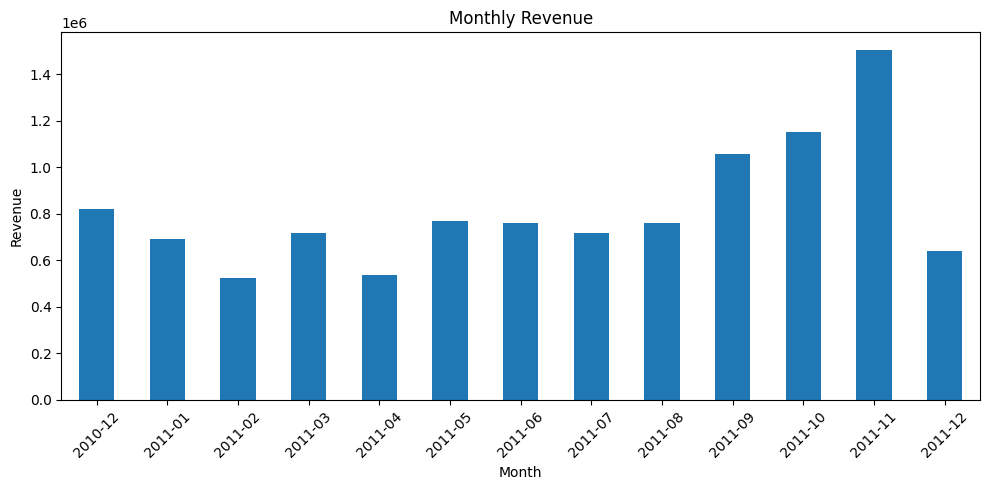

In [31]:
import matplotlib.pyplot as plt
monthly_revenue.plot(kind="bar", figsize=(10, 5))
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
top_products = sales_data.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)

display(top_products)

,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
JUMBO BAG RED RETROSPOT,48371
WHITE HANGING HEART T-LIGHT HOLDER,37872
POPCORN HOLDER,36749
PACK OF 72 RETROSPOT CAKE CASES,36396
ASSORTED COLOUR BIRD ORNAMENT,36362
RABBIT NIGHT LIGHT,30739


In [33]:
top_revenue_products = (
    sales_data.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_revenue_products)

,Revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


In [34]:
country_revenue = (
    sales_data.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(country_revenue)

,Revenue
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


In [35]:
customer_revenue = (
    sales_data.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(customer_revenue)

,Revenue
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194390.79
16446.0,168472.50
14911.0,143711.17
12415.0,124914.53
14156.0,117210.08
17511.0,91062.38
16029.0,80850.84


In [36]:
customer_orders = (
    sales_data.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

display(customer_orders)

,InvoiceNo
CustomerID,
12748.0,209
14911.0,201
17841.0,124
13089.0,97
14606.0,93
15311.0,91
12971.0,86
14646.0,73
16029.0,63


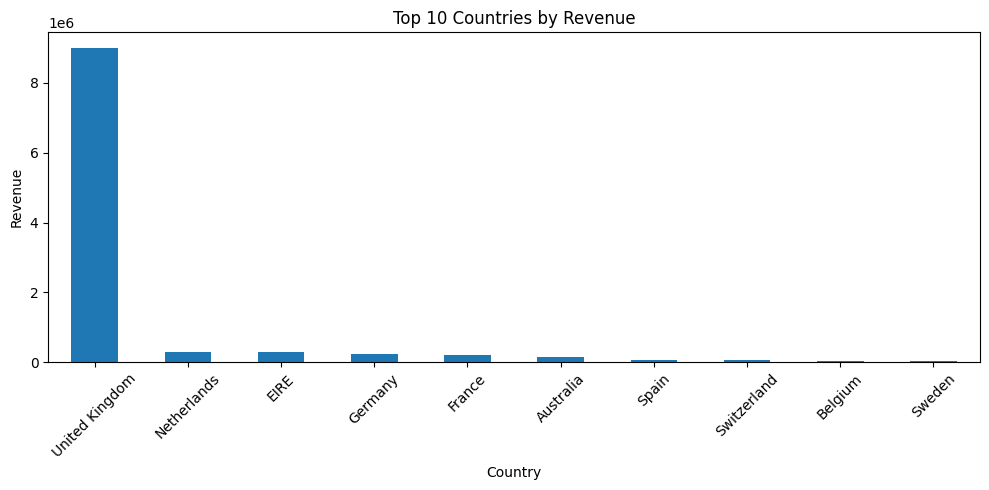

In [37]:
country_revenue.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
customer_spending = sales_data.groupby("CustomerID")["Revenue"].sum()

customer_spending.describe().round(2)

,Revenue
count,4338.00
mean,2048.69
std,8985.23
min,3.75
25%,306.48
50%,668.57
75%,1660.60
max,280206.02


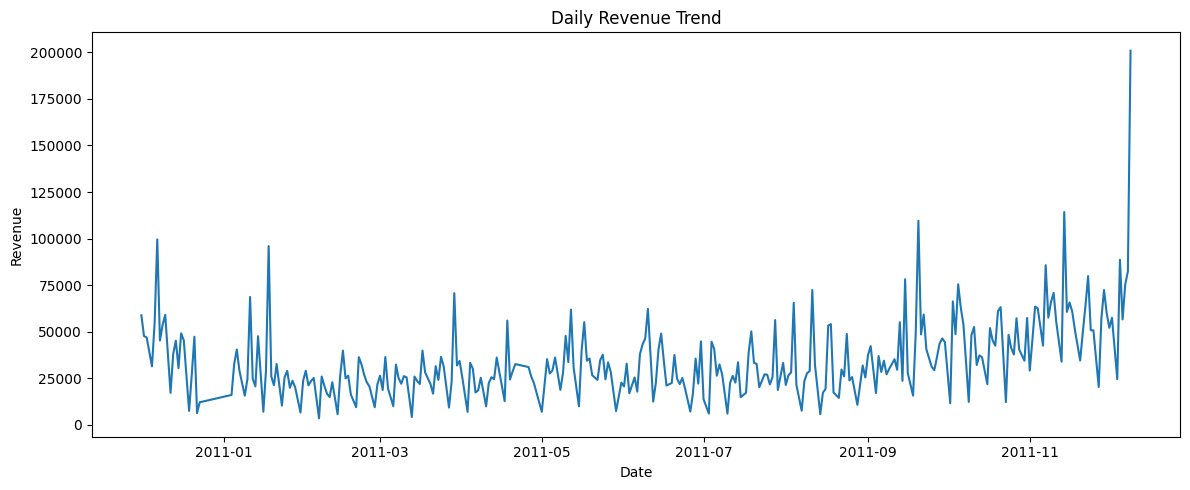

In [39]:
sales_data["Date"] = sales_data["InvoiceDate"].dt.date
daily_revenue = sales_data.groupby("Date")["Revenue"].sum()
daily_revenue.plot(figsize=(12, 5))
plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [40]:
best_day = daily_revenue.idxmax()
best_revenue = daily_revenue.max()

print("Highest-revenue date:", best_day)
print("Revenue on that day:", round(best_revenue, 2))

Highest-revenue date: 2011-12-09
Revenue on that day: 200900.98


In [41]:
print("Total product-sales revenue:", round(sales_data["Revenue"].sum(), 2))
print("Number of customers:", sales_data["CustomerID"].nunique())
print("Number of unique products:", sales_data["Description"].nunique())
print("Number of countries:", sales_data["Country"].nunique())
print("Number of unique invoices:", sales_data["InvoiceNo"].nunique())

Total product-sales revenue: 10642110.8
Number of customers: 4338
Number of unique products: 4026
Number of countries: 38
Number of unique invoices: 19960


In [42]:
# STEP 31: Prepare customer-level data
customer_data = sales_data.groupby("CustomerID").agg(
    TotalSpend=("Revenue", "sum"),
    TotalOrders=("InvoiceNo", "nunique"),
    LastPurchase=("InvoiceDate", "max")
).reset_index()
display(customer_data.head(10))
print("Number of customers:", len(customer_data))
print("Dataset shape:", customer_data.shape)

,CustomerID,TotalSpend,TotalOrders,LastPurchase
0,12346.0,77183.60,1,2011-01-18 10:01:00
1,12347.0,4310.00,7,2011-12-07 15:52:00
2,12348.0,1797.24,4,2011-09-25 13:13:00
3,12349.0,1757.55,1,2011-11-21 09:51:00
4,12350.0,334.40,1,2011-02-02 16:01:00
5,12352.0,2506.04,8,2011-11-03 14:37:00
6,12353.0,89.00,1,2011-05-19 17:47:00
7,12354.0,1079.40,1,2011-04-21 13:11:00
8,12355.0,459.40,1,2011-05-09 13:49:00
9,12356.0,2811.43,3,2011-11-17 08:40:00


Number of customers: 4338
Dataset shape: (4338, 4)


In [43]:

# STEP 32: Calculate customer recency

reference_date = sales_data["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_data["Recency"] = (
    reference_date - customer_data["LastPurchase"]
).dt.days

display(customer_data[[
    "CustomerID", "LastPurchase", "Recency"
]].head(10))


,CustomerID,LastPurchase,Recency
0,12346.0,2011-01-18 10:01:00,326
1,12347.0,2011-12-07 15:52:00,2
2,12348.0,2011-09-25 13:13:00,75
3,12349.0,2011-11-21 09:51:00,19
4,12350.0,2011-02-02 16:01:00,310
5,12352.0,2011-11-03 14:37:00,36
6,12353.0,2011-05-19 17:47:00,204
7,12354.0,2011-04-21 13:11:00,232
8,12355.0,2011-05-09 13:49:00,214
9,12356.0,2011-11-17 08:40:00,23


In [44]:

# STEP 33: Analyse customer purchase frequency

customer_frequency = customer_data[
    ["CustomerID", "TotalOrders"]
].sort_values(
    "TotalOrders", ascending=False
)

display(customer_frequency.head(10))


,CustomerID,TotalOrders
326,12748.0,209
1879,14911.0,201
4010,17841.0,124
562,13089.0,97
1661,14606.0,93
2176,15311.0,91
481,12971.0,86
1689,14646.0,73
2702,16029.0,63
795,13408.0,62


In [45]:

# STEP 34: Analyse customer monetary value

customer_monetary = customer_data[
    ["CustomerID", "TotalSpend"]
].sort_values(
    "TotalSpend", ascending=False
)

display(customer_monetary.head(10))


,CustomerID,TotalSpend
1689,14646.0,280206.02
4201,18102.0,259657.30
3728,17450.0,194390.79
3008,16446.0,168472.50
1879,14911.0,143711.17
55,12415.0,124914.53
1333,14156.0,117210.08
3771,17511.0,91062.38
2702,16029.0,80850.84
0,12346.0,77183.60


In [46]:
# STEP 35: Combine RFM metrics
rfm = customer_data[
    ["CustomerID", "Recency", "TotalOrders", "TotalSpend"]
].copy()
rfm = rfm.rename(columns={
    "TotalOrders": "Frequency",
    "TotalSpend": "Monetary"
})
display(rfm.head(10))
print("RFM dataset shape:", rfm.shape)

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40
5,12352.0,36,8,2506.04
6,12353.0,204,1,89.00
7,12354.0,232,1,1079.40
8,12355.0,214,1,459.40
9,12356.0,23,3,2811.43


RFM dataset shape: (4338, 4)


In [47]:
# STEP 36: Assign RFM scores

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

display(rfm.head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346.0,326,1,77183.60,1,1,4
1,12347.0,2,7,4310.00,4,4,4
2,12348.0,75,4,1797.24,2,3,4
3,12349.0,19,1,1757.55,3,1,4
4,12350.0,310,1,334.40,1,1,2
5,12352.0,36,8,2506.04,3,4,4
6,12353.0,204,1,89.00,1,1,1
7,12354.0,232,1,1079.40,1,1,3
8,12355.0,214,1,459.40,1,1,2
9,12356.0,23,3,2811.43,3,3,4


In [48]:
# STEP 37: Create customer segments

def segment_customer(row):
    if row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal / Active"
    elif row["R_Score"] <= 2 and row["M_Score"] >= 3:
        return "At-Risk High-Value"
    elif row["R_Score"] >= 3 and row["F_Score"] <= 2:
        return "Recent / Low-Frequency"
    else:
        return "Needs Attention"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)

display(rfm[
    ["CustomerID", "Recency", "Frequency", "Monetary",
     "R_Score", "F_Score", "M_Score", "Segment"]
].head(15))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,Segment
0,12346.0,326,1,77183.60,1,1,4,At-Risk High-Value
1,12347.0,2,7,4310.00,4,4,4,Loyal / Active
2,12348.0,75,4,1797.24,2,3,4,At-Risk High-Value
3,12349.0,19,1,1757.55,3,1,4,Recent / Low-Frequency
4,12350.0,310,1,334.40,1,1,2,Needs Attention
5,12352.0,36,8,2506.04,3,4,4,Loyal / Active
6,12353.0,204,1,89.00,1,1,1,Needs Attention
7,12354.0,232,1,1079.40,1,1,3,At-Risk High-Value
8,12355.0,214,1,459.40,1,1,2,Needs Attention
9,12356.0,23,3,2811.43,3,3,4,Loyal / Active


In [49]:
# STEP 38: Count customers in each segment
segment_counts = rfm["Segment"].value_counts()
display(segment_counts)
print("\nPercentage of customers in each segment:")
display((segment_counts / len(rfm) * 100).round(2))

,count
Segment,
Loyal / Active,1514
Needs Attention,1446
At-Risk High-Value,723
Recent / Low-Frequency,655



Percentage of customers in each segment:


,count
Segment,
Loyal / Active,34.90
Needs Attention,33.33
At-Risk High-Value,16.67
Recent / Low-Frequency,15.10


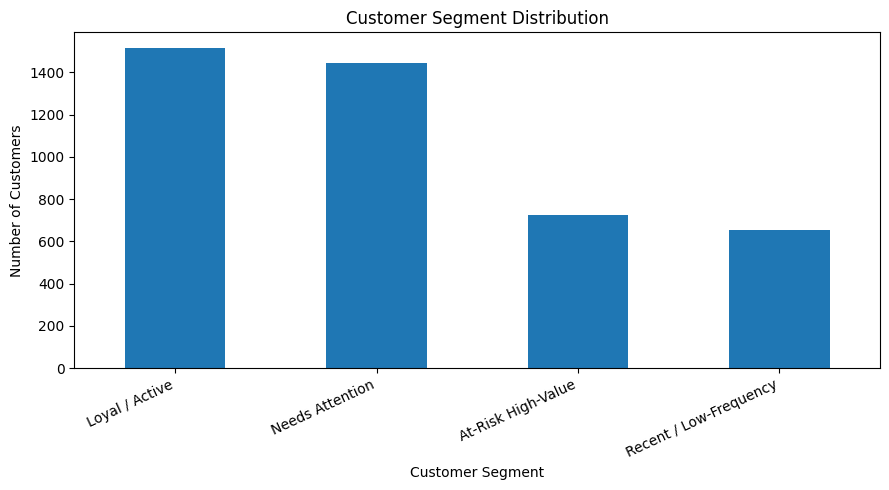

In [50]:
# STEP 39: Visualize customer segments

import matplotlib.pyplot as plt

segment_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [51]:
# STEP 40: Revenue by customer segment

segment_revenue = (
    rfm.groupby("Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
)

display(segment_revenue)

print("\nRevenue percentage by segment:")
display(
    (segment_revenue / segment_revenue.sum() * 100).round(2)
)

,Monetary
Segment,
Loyal / Active,6569940.811
At-Risk High-Value,1385518.341
Recent / Low-Frequency,493878.820
Needs Attention,437870.922



Revenue percentage by segment:


,Monetary
Segment,
Loyal / Active,73.93
At-Risk High-Value,15.59
Recent / Low-Frequency,5.56
Needs Attention,4.93


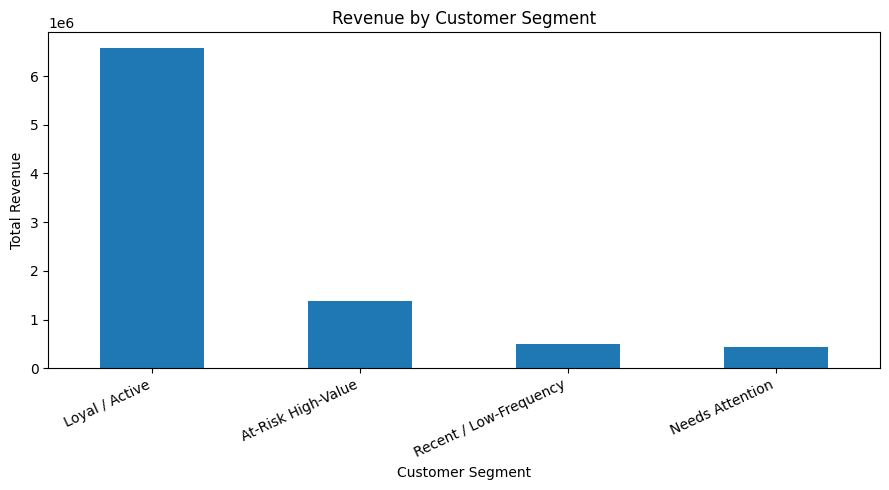

In [52]:
# STEP 41: Visualize revenue by customer segment

segment_revenue.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [53]:
# STEP 42: Phase 3 final summary

print("PHASE 3: CUSTOMER SEGMENTATION — SUMMARY")
print("-" * 45)

print("Total customers analysed:", len(rfm))
print("\nCustomer segments:")
display(segment_counts)

print("\nRevenue by segment:")
display(segment_revenue.round(2))

print("\nHighest-revenue segment:", segment_revenue.idxmax())
print("Revenue contribution (%):")
display((segment_revenue / segment_revenue.sum() * 100).round(2))

print("\nPHASE 3 COMPLETE!")

PHASE 3: CUSTOMER SEGMENTATION — SUMMARY
---------------------------------------------
Total customers analysed: 4338

Customer segments:


,count
Segment,
Loyal / Active,1514
Needs Attention,1446
At-Risk High-Value,723
Recent / Low-Frequency,655



Revenue by segment:


,Monetary
Segment,
Loyal / Active,6569940.81
At-Risk High-Value,1385518.34
Recent / Low-Frequency,493878.82
Needs Attention,437870.92



Highest-revenue segment: Loyal / Active
Revenue contribution (%):


,Monetary
Segment,
Loyal / Active,73.93
At-Risk High-Value,15.59
Recent / Low-Frequency,5.56
Needs Attention,4.93



PHASE 3 COMPLETE!


In [54]:
# STEP 43: Check the dataset date range

print("First transaction:", sales_data["InvoiceDate"].min())
print("Last transaction:", sales_data["InvoiceDate"].max())

First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00


In [55]:
# STEP 44: Define the observation and prediction windows

observation_end = pd.Timestamp("2011-09-30")
prediction_start = pd.Timestamp("2011-10-01")
prediction_end = pd.Timestamp("2011-11-30")

print("Observation window ends:", observation_end)
print("Prediction window starts:", prediction_start)
print("Prediction window ends:", prediction_end)

Observation window ends: 2011-09-30 00:00:00
Prediction window starts: 2011-10-01 00:00:00
Prediction window ends: 2011-11-30 00:00:00


In [56]:
# STEP 45: Filter transactions in the observation window

observation_data = sales_data[
    sales_data["InvoiceDate"] <= observation_end
].copy()

print("Observation transactions:", len(observation_data))
print("Unique customers:", observation_data["CustomerID"].nunique())
print("Date range:", observation_data["InvoiceDate"].min(),
      "to", observation_data["InvoiceDate"].max())

Observation transactions: 357665
Unique customers: 3604
Date range: 2010-12-01 08:26:00 to 2011-09-29 19:30:00


In [57]:
# STEP 46: Filter transactions in the prediction window

prediction_data = sales_data[
    (sales_data["InvoiceDate"] >= prediction_start) &
    (sales_data["InvoiceDate"] <= prediction_end)
].copy()

print("Prediction transactions:", len(prediction_data))
print("Unique customers:", prediction_data["CustomerID"].nunique())
print("Date range:", prediction_data["InvoiceDate"].min(),
      "to", prediction_data["InvoiceDate"].max())

Prediction transactions: 137200
Unique customers: 2384
Date range: 2011-10-02 10:32:00 to 2011-11-29 18:14:00


In [58]:
# STEP 47: Label customers as active or inactive

future_customers = prediction_data["CustomerID"].unique()

customer_data = pd.DataFrame({
    "CustomerID": observation_data["CustomerID"].unique()
})

customer_data["Inactive"] = (
    ~customer_data["CustomerID"].isin(future_customers)
).astype(int)

print(customer_data["Inactive"].value_counts())
print("\nInactivity percentage:")
print((customer_data["Inactive"].mean() * 100).round(2), "%")

Inactive
1    1899
0    1706
Name: count, dtype: int64

Inactivity percentage:
52.68 %


In [59]:
# STEP 48: Check for missing customer IDs

print("Missing IDs in observation data:",
      observation_data["CustomerID"].isna().sum())

print("Missing IDs in customer labels:",
      customer_data["CustomerID"].isna().sum())

customer_data = customer_data.dropna(subset=["CustomerID"]).copy()

print("Customers after removing missing IDs:", len(customer_data))
print("\nLabel counts:")
print(customer_data["Inactive"].value_counts())

Missing IDs in observation data: 95411
Missing IDs in customer labels: 1
Customers after removing missing IDs: 3604

Label counts:
Inactive
1    1899
0    1705
Name: count, dtype: int64


In [60]:
# STEP 49: Create customer behaviour features

features = observation_data.dropna(subset=["CustomerID"]).groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (observation_end - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum")
).reset_index()

print("Feature dataset shape:", features.shape)
print(features.head())

Feature dataset shape: (3604, 5)
   CustomerID  Recency  Frequency  Monetary  TotalQuantity
0     12346.0      254          1  77183.60          74215
1     12347.0       58          5   2790.86           1590
2     12348.0        4          4   1797.24           2341
3     12350.0      239          1    334.40            197
4     12352.0        1          7   2194.31            409


In [61]:
# STEP 50: Combine features and labels

ml_data = features.merge(customer_data, on="CustomerID", how="inner")

print("ML dataset shape:", ml_data.shape)
print("\nMissing values:")
print(ml_data.isna().sum())
print("\nInactivity distribution:")
print(ml_data["Inactive"].value_counts())

ML dataset shape: (3604, 6)

Missing values:
CustomerID       0
Recency          0
Frequency        0
Monetary         0
TotalQuantity    0
Inactive         0
dtype: int64

Inactivity distribution:
Inactive
1    1899
0    1705
Name: count, dtype: int64


In [62]:
# STEP 51: Separate features and target

X = ml_data[["Recency", "Frequency", "Monetary", "TotalQuantity"]]
y = ml_data["Inactive"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Feature matrix shape: (3604, 4)
Target shape: (3604,)

Target classes:
Inactive
1    1899
0    1705
Name: count, dtype: int64


In [63]:
# STEP 52: Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining label distribution:")
print(y_train.value_counts())
print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 2883
Testing samples: 721

Training label distribution:
Inactive
1    1519
0    1364
Name: count, dtype: int64

Testing label distribution:
Inactive
1    380
0    341
Name: count, dtype: int64


In [64]:
# STEP 53: Train the Random Forest model

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [65]:
# STEP 54: Generate predictions on test data

y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print("\nFirst 10 actual labels:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10])

Predictions generated successfully!

First 10 actual labels:
[1, 1, 1, 0, 0, 0, 1, 0, 1, 1]

First 10 predicted labels:
[1 1 0 0 1 0 1 0 1 1]


In [66]:
# STEP 55: Evaluate model performance

from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Active", "Inactive"]
))

Accuracy: 0.6616

Classification Report:
              precision    recall  f1-score   support

      Active       0.66      0.59      0.62       341
    Inactive       0.66      0.73      0.69       380

    accuracy                           0.66       721
   macro avg       0.66      0.66      0.66       721
weighted avg       0.66      0.66      0.66       721



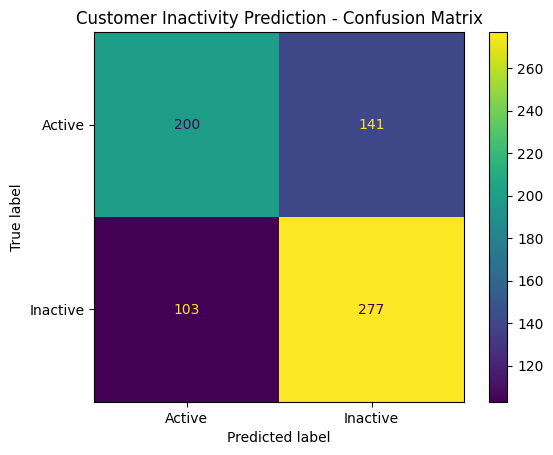

In [67]:
# STEP 56: Display the confusion matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Active", "Inactive"]
)

display.plot()
plt.title("Customer Inactivity Prediction - Confusion Matrix")
plt.show()

In [68]:
# STEP 57: Feature importance

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance.round(4))

Monetary         0.3283
TotalQuantity    0.2838
Recency          0.2592
Frequency        0.1287
dtype: float64


In [69]:
# STEP 58: Phase 4 summary

print("PHASE 4: PREDICTIVE ANALYTICS")
print("Customers analysed:", len(ml_data))
print("Model: Random Forest Classifier")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Inactive customer recall:",
      round(classification_report(
          y_test, y_pred, output_dict=True
      )["1"]["recall"] * 100, 2), "%")

print("\nMost important feature:", importance.index[0])
print("\nPhase 4 completed successfully!")

PHASE 4: PREDICTIVE ANALYTICS
Customers analysed: 3604
Model: Random Forest Classifier
Accuracy: 66.16 %
Inactive customer recall: 72.89 %

Most important feature: Monetary

Phase 4 completed successfully!


In [70]:
# STEP 59: Check dataframes for the dashboard

print("Sales data:", sales_data.shape)
print("RFM data:", rfm.shape)
print("Customer features:", features.shape)
print("ML results:", ml_data.shape)

Sales data: (524878, 11)
RFM data: (4338, 8)
Customer features: (3604, 5)
ML results: (3604, 6)


In [71]:
# STEP 60: Prepare prediction results for the dashboard

prediction_results = X_test.copy()
prediction_results["Actual_Inactive"] = y_test
prediction_results["Predicted_Inactive"] = y_pred

print("Prediction results shape:", prediction_results.shape)
print(prediction_results.head())

Prediction results shape: (721, 6)
      Recency  Frequency  Monetary  TotalQuantity  Actual_Inactive  \
2592      302          1    233.45            111                1   
245        80          2   1030.98            506                1   
3543       94          1    243.76            124                1   
76         10          6   2166.88            810                0   
2253      109          1    161.90             44                0   

      Predicted_Inactive  
2592                   1  
245                    1  
3543                   0  
76                     0  
2253                   1  


In [72]:
# STEP 61: Export data for the dashboard

sales_data.to_csv("sales_data.csv", index=False)
rfm.to_csv("rfm_segments.csv", index=False)
prediction_results.to_csv("prediction_results.csv", index=False)

print("Dashboard datasets exported successfully!")

Dashboard datasets exported successfully!


In [73]:
# STEP 62: Download dashboard datasets

from google.colab import files

files.download("sales_data.csv")
files.download("rfm_segments.csv")
files.download("prediction_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>